# Analisis Statistika Deskriptif Konsumsi Listrik Harian Berdasarkan Waktu dan Kondisi Cuaca

**Deskripsi Proyek**

Proyek ini bertujuan untuk menggambarkan karakteristik konsumsi listrik harian berdasarkan data waktu dan kondisi cuaca. Analisis dilakukan menggunakan statistika deskriptif, tabel resume, dan visualisasi data untuk memudahkan pembaca memahami pola yang terlihat selama periode pengamatan.

Seluruh proses analisis dilakukan menggunakan Python pada Google Colab dengan dataset konsumsi listrik harian dan data cuaca.

**Import library dan upload dataset**

In [ ]:
# Model 1: Persiapan dan Input Data

from google.colab import files
from IPython.display import display, HTML
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Upload file Excel
berkas = files.upload()

# Mengambil nama file yang di-upload
nama_file = next(iter(berkas))

print("File berhasil di-upload:", nama_file)

Saving Kelompok10_3TIA.xlsx to Kelompok10_3TIA.xlsx
File berhasil di-upload: Kelompok10_3TIA.xlsx


**Membaca dan memeriksa dataset**

In [ ]:
# Model 2: Pemeriksaan Dataset

data = pd.read_excel(nama_file, sheet_name="Data")

# Mengganti nama kolom menjadi lebih ringkas
data = data.rename(columns={
    "Kecepatan Angin (m/s)": "Angin",
    "Curah Hujan (mm)": "Hujan",
    "Suhu Maks (°C)": "Suhu_Maks",
    "Suhu Min (°C)": "Suhu_Min",
    "Konsumsi Listrik Harian": "Listrik"
})

# Memastikan format data benar
data["Tanggal"] = pd.to_datetime(data["Tanggal"], errors="coerce")

angka = ["Angin", "Hujan", "Suhu_Maks", "Suhu_Min", "Listrik"]

for kolom in angka:
    data[kolom] = pd.to_numeric(data[kolom], errors="coerce")

# Mengurutkan data berdasarkan tanggal
data = data.sort_values("Tanggal").reset_index(drop=True)

# Menyimpan salinan dataset asli sebelum menambahkan kolom analisis
data_asli = data.copy()

# Menampilkan data awal
print("Lima baris pertama:")
display(data.head())

print("Jumlah baris:", len(data))
print("Jumlah kolom:", len(data.columns))

print("\nData kosong setiap kolom:")
display(data.isna().sum().rename("Jumlah Kosong").to_frame())

print("\nJumlah baris yang sama persis:", data.duplicated().sum())
print("Jumlah tanggal yang berulang:", data["Tanggal"].duplicated().sum())

# Memeriksa rentang waktu
awal = data["Tanggal"].min()
akhir = data["Tanggal"].max()

hari_total = (akhir - awal).days + 1
hari_tercatat = data["Tanggal"].nunique()
hari_kosong = hari_total - hari_tercatat

print("\nTanggal awal:", awal.date())
print("Tanggal akhir:", akhir.date())
print("Jumlah tanggal dalam rentang:", hari_total)
print("Jumlah tanggal yang tercatat:", hari_tercatat)
print("Tanggal yang tidak tercatat:", hari_kosong)

# Melihat konsumsi listrik terendah untuk pemeriksaan
print("\nSepuluh nilai konsumsi listrik terendah:")
display(
    data.nsmallest(10, "Listrik")[
        ["Tanggal", "Listrik", "Hujan", "Suhu_Maks", "Suhu_Min"]
    ]
)

Lima baris pertama:


,Tanggal,Angin,Hujan,Suhu_Maks,Suhu_Min,Listrik
0,2006-12-16,2.5,0.0,10.6,5.0,1209.176
1,2006-12-17,2.6,0.0,13.3,5.6,3390.460
2,2006-12-18,2.4,0.0,15.0,6.7,2203.826
3,2006-12-19,2.4,0.0,7.2,2.2,1666.194
4,2006-12-20,2.4,0.0,7.2,1.1,2225.748


Jumlah baris: 1433
Jumlah kolom: 6

Data kosong setiap kolom:


,Jumlah Kosong
Tanggal,0
Angin,0
Hujan,0
Suhu_Maks,0
Suhu_Min,0
Listrik,0



Jumlah baris yang sama persis: 0
Jumlah tanggal yang berulang: 0

Tanggal awal: 2006-12-16
Tanggal akhir: 2010-11-26
Jumlah tanggal dalam rentang: 1442
Jumlah tanggal yang tercatat: 1433
Tanggal yang tidak tercatat: 9

Sepuluh nilai konsumsi listrik terendah:


,Tanggal,Listrik,Hujan,Suhu_Maks,Suhu_Min
909,2009-06-13,14.218,3.3,22.8,16.1
133,2007-04-28,22.738,0.0,21.7,12.2
1338,2010-08-22,93.338,42.9,26.7,20.6
1372,2010-09-25,106.006,0.0,31.7,19.4
1187,2010-03-20,131.732,0.0,23.3,12.2
617,2008-08-25,250.298,0.0,29.4,19.4
615,2008-08-23,254.642,0.0,27.2,18.9
616,2008-08-24,254.716,0.0,27.8,20.0
618,2008-08-26,257.564,0.0,26.7,16.1
619,2008-08-27,258.114,0.0,26.1,16.1


# **Deskripsi data dan jenis variabel**

**Ringkasan profil data dan skala pengukuran**

In [ ]:
# Model 3: Profil Data dan Jenis Variabel

profil = pd.DataFrame({
    "Keterangan": [
        "Nama file",
        "Jumlah observasi",
        "Jumlah variabel",
        "Variabel numerik",
        "Tanggal awal",
        "Tanggal akhir",
        "Tanggal tidak tercatat"
    ],
    "Nilai": [
        nama_file,
        len(data_asli),
        len(data_asli.columns),
        len(angka),
        awal.date(),
        akhir.date(),
        hari_kosong
    ]
})

display(profil)

# Tabel jenis data dan skala pengukuran
tabel_skala = pd.DataFrame({
    "Variabel": [
        "Tanggal",
        "Kecepatan Angin",
        "Curah Hujan",
        "Suhu Maksimum",
        "Suhu Minimum",
        "Konsumsi Listrik Harian"
    ],
    "Jenis Data": [
        "Tanggal/waktu",
        "Numerik kontinu",
        "Numerik kontinu",
        "Numerik kontinu",
        "Numerik kontinu",
        "Numerik"
    ],
    "Skala Pengukuran": [
        "Interval (temporal)",
        "Rasio",
        "Rasio",
        "Interval",
        "Interval",
        "Rasio"
    ],
    "Keterangan": [
        "Menunjukkan tanggal pengamatan",
        "Kecepatan angin dalam m/s",
        "Curah hujan dalam mm",
        "Suhu dalam Celsius",
        "Suhu dalam Celsius",
        "Satuan tidak dicantumkan dalam file"
    ]
})

display(tabel_skala)

,Keterangan,Nilai
0,Nama file,Kelompok10_3TIA.xlsx
1,Jumlah observasi,1433
2,Jumlah variabel,6
3,Variabel numerik,5
4,Tanggal awal,2006-12-16
5,Tanggal akhir,2010-11-26
6,Tanggal tidak tercatat,9


,Variabel,Jenis Data,Skala Pengukuran,Keterangan
0,Tanggal,Tanggal/waktu,Interval (temporal),Menunjukkan tanggal pengamatan
1,Kecepatan Angin,Numerik kontinu,Rasio,Kecepatan angin dalam m/s
2,Curah Hujan,Numerik kontinu,Rasio,Curah hujan dalam mm
3,Suhu Maksimum,Numerik kontinu,Interval,Suhu dalam Celsius
4,Suhu Minimum,Numerik kontinu,Interval,Suhu dalam Celsius
5,Konsumsi Listrik Harian,Numerik,Rasio,Satuan tidak dicantumkan dalam file


# **BAGIAN 3 — Tabel statistik deskriptif**

**Perhitungan 18 ukuran statistik**

In [ ]:
# Model 4: Tabel Statistik Deskriptif

def hitung(s, nama):
    s = s.dropna()
    frekuensi = s.value_counts()

    # Menghitung modus
    if frekuensi.empty:
        modus = "Tidak tersedia"
    elif frekuensi.max() == 1:
        modus = "Tidak ada modus tunggal"
    else:
        nilai_modus = frekuensi[frekuensi == frekuensi.max()].index.tolist()
        modus = ", ".join(f"{x:.3f}" for x in nilai_modus[:3])

        if len(nilai_modus) > 3:
            modus += ", dan lainnya"

    # Menghitung kuartil
    q1 = s.quantile(0.25)
    q2 = s.quantile(0.50)
    q3 = s.quantile(0.75)

    # CV hanya untuk variabel berskala rasio
    cv = np.nan

    if nama in ["Angin", "Hujan", "Listrik"] and s.mean() != 0:
        cv = s.std(ddof=1) / s.mean() * 100

    return {
        "Variabel": nama,
        "Count": s.count(),
        "Jumlah": s.sum(),
        "Mean": s.mean(),
        "Modus": modus,
        "Median": s.median(),
        "SE": s.std(ddof=1) / np.sqrt(s.count()),
        "Std Dev": s.std(ddof=1),
        "Varian": s.var(ddof=1),
        "Q1": q1,
        "Q2": q2,
        "Q3": q3,
        "IQR": q3 - q1,
        "Skewness": s.skew(),
        "Kurtosis": s.kurt(),
        "Min": s.min(),
        "Max": s.max(),
        "Range": s.max() - s.min(),
        "CV (%)": cv
    }


# Menghitung statistik untuk semua variabel numerik
hasil = []

for kolom in angka:
    hasil.append(hitung(data[kolom], kolom))

tabel_stat = pd.DataFrame(hasil)

# Mengubah nama variabel agar lebih mudah dibaca
label = {
    "Angin": "Kecepatan Angin (m/s)",
    "Hujan": "Curah Hujan (mm)",
    "Suhu_Maks": "Suhu Maksimum (°C)",
    "Suhu_Min": "Suhu Minimum (°C)",
    "Listrik": "Konsumsi Listrik Harian"
}

tabel_stat["Variabel"] = tabel_stat["Variabel"].map(label)

print("Tabel Statistik Deskriptif")
display(tabel_stat.round(3))

Tabel Statistik Deskriptif


,Variabel,Count,Jumlah,Mean,Modus,Median,SE,Std Dev,Varian,Q1,Q2,Q3,IQR,Skewness,Kurtosis,Min,Max,Range,CV (%)
0,Kecepatan Angin (m/s),1433,3775.900,2.635,2.200,2.40,0.030,1.137,1.292,1.8,2.40,3.200,1.400,0.975,1.835,0.000,10.200,10.200,43.146
1,Curah Hujan (mm),1433,5446.100,3.800,0.000,0.00,0.290,10.973,120.416,0.0,0.00,1.300,1.300,6.371,72.460,0.000,192.300,192.300,288.738
2,Suhu Maksimum (°C),1433,24629.700,17.188,28.300,17.80,0.268,10.136,102.747,8.9,17.80,26.100,17.200,-0.213,-0.990,-8.900,39.400,48.300,NaN
3,Suhu Minimum (°C),1433,13099.400,9.141,19.400,9.40,0.239,9.028,81.512,2.2,9.40,17.200,15.000,-0.236,-0.871,-14.400,27.200,41.600,NaN
4,Konsumsi Listrik Harian,1433,2237024.862,1561.078,Tidak ada modus tunggal,1542.65,16.030,606.820,368230.109,1165.7,1542.65,1893.608,727.908,0.520,1.215,14.218,4773.386,4759.168,38.872


**Tabel resume utama**

In [ ]:
# Model 5: Tabel Resume

tabel_resume = tabel_stat[
    [
        "Variabel",
        "Count",
        "Mean",
        "Median",
        "Std Dev",
        "Min",
        "Max"
    ]
].copy()

tabel_resume = tabel_resume.rename(columns={
    "Count": "Jumlah Data",
    "Mean": "Rata-rata",
    "Median": "Nilai Tengah",
    "Std Dev": "Standar Deviasi",
    "Min": "Nilai Minimum",
    "Max": "Nilai Maksimum"
})

print("Tabel Resume Statistik Deskriptif")
display(tabel_resume.round(3))

Tabel Resume Statistik Deskriptif


,Variabel,Jumlah Data,Rata-rata,Nilai Tengah,Standar Deviasi,Nilai Minimum,Nilai Maksimum
0,Kecepatan Angin (m/s),1433,2.635,2.40,1.137,0.000,10.200
1,Curah Hujan (mm),1433,3.800,0.00,10.973,0.000,192.300
2,Suhu Maksimum (°C),1433,17.188,17.80,10.136,-8.900,39.400
3,Suhu Minimum (°C),1433,9.141,9.40,9.028,-14.400,27.200
4,Konsumsi Listrik Harian,1433,1561.078,1542.65,606.820,14.218,4773.386


# **BAGIAN 4 — Tabel frekuensi dan probabilitas empiris**

**Kategori konsumsi dan peluang empiris**

In [ ]:
# Model 6: Tabel Frekuensi dan Probabilitas Empiris

q1 = data["Listrik"].quantile(0.25)
q3 = data["Listrik"].quantile(0.75)

# Membentuk kategori berdasarkan kuartil
data["Kategori"] = pd.cut(
    data["Listrik"],
    bins=[-np.inf, q1, q3, np.inf],
    labels=["Rendah", "Sedang", "Tinggi"],
    right=False
)

# Tabel frekuensi
tabel_freq = (
    data["Kategori"]
    .value_counts(sort=False)
    .reindex(["Rendah", "Sedang", "Tinggi"], fill_value=0)
    .rename_axis("Kategori")
    .reset_index(name="Jumlah Hari")
)

jumlah_valid = data["Listrik"].count()

tabel_freq["Persentase (%)"] = (
    tabel_freq["Jumlah Hari"] / jumlah_valid * 100
).round(2)

print("Tabel Frekuensi Kategori Konsumsi Listrik")
display(tabel_freq)

# Probabilitas empiris konsumsi tinggi
jumlah_tinggi = (data["Listrik"] >= q3).sum()

peluang = jumlah_tinggi / jumlah_valid

tabel_emp = pd.DataFrame({
    "Keterangan": [
        "Batas konsumsi tinggi (Q3)",
        "Jumlah hari dengan konsumsi tinggi",
        "Jumlah hari dengan data valid",
        "Proporsi empiris konsumsi tinggi (%)"
    ],
    "Nilai": [
        round(q3, 3),
        int(jumlah_tinggi),
        int(jumlah_valid),
        round(peluang * 100, 2)
    ]
})

print("Tabel Probabilitas Empiris")
display(tabel_emp)

Tabel Frekuensi Kategori Konsumsi Listrik


,Kategori,Jumlah Hari,Persentase (%)
0,Rendah,358,24.98
1,Sedang,716,49.97
2,Tinggi,359,25.05


Tabel Probabilitas Empiris


,Keterangan,Nilai
0,Batas konsumsi tinggi (Q3),1893.608
1,Jumlah hari dengan konsumsi tinggi,359.000
2,Jumlah hari dengan data valid,1433.000
3,Proporsi empiris konsumsi tinggi (%),25.050


# **BAGIAN 5 — Analisis berdasarkan waktu**

**Tabel resume berdasarkan hari dalam seminggu**

In [ ]:
# Model 7: Ringkasan Konsumsi Menurut Hari

nama_hari = {
    0: "Senin",
    1: "Selasa",
    2: "Rabu",
    3: "Kamis",
    4: "Jumat",
    5: "Sabtu",
    6: "Minggu"
}

data["Hari"] = data["Tanggal"].dt.dayofweek.map(nama_hari)

tabel_hari = data.groupby("Hari")["Listrik"].agg(
    Jumlah="count",
    Rata_rata="mean",
    Median="median",
    Minimum="min",
    Maksimum="max"
)

# Mengatur urutan hari agar sesuai kalender
urut_hari = [
    "Senin", "Selasa", "Rabu", "Kamis",
    "Jumat", "Sabtu", "Minggu"
]

tabel_hari = tabel_hari.reindex(urut_hari)

tabel_hari.columns = [
    "Jumlah Hari",
    "Rata-rata Listrik",
    "Median Listrik",
    "Nilai Minimum",
    "Nilai Maksimum"
]

print("Tabel Resume Berdasarkan Hari")
display(tabel_hari.round(3))

Tabel Resume Berdasarkan Hari


,Jumlah Hari,Rata-rata Listrik,Median Listrik,Nilai Minimum,Nilai Maksimum
Hari,,,,,
Senin,205,1432.852,1443.260,250.298,3212.998
Selasa,206,1530.587,1518.774,257.564,3934.110
Rabu,204,1558.390,1583.147,258.114,3134.930
Kamis,205,1404.026,1394.186,261.298,3369.478
Jumat,205,1501.536,1497.768,267.124,3174.392
Sabtu,205,1758.770,1733.138,14.218,4773.386
Minggu,203,1743.300,1674.356,93.338,3829.762


**Tabel ringkasan berdasarkan kondisi hujan**

In [ ]:
# Model 8: Ringkasan Konsumsi Berdasarkan Kondisi Hujan

data["Cuaca"] = np.where(
    data["Hujan"] > 0,
    "Ada hujan",
    "Tidak ada hujan"
)

tabel_cuaca = data.groupby("Cuaca")["Listrik"].agg(
    Jumlah="count",
    Rata_rata="mean",
    Median="median",
    Minimum="min",
    Maksimum="max"
)

tabel_cuaca = tabel_cuaca.reindex([
    "Ada hujan",
    "Tidak ada hujan"
])

tabel_cuaca.columns = [
    "Jumlah Hari",
    "Rata-rata Listrik",
    "Median Listrik",
    "Nilai Minimum",
    "Nilai Maksimum"
]

print("Tabel Resume Berdasarkan Kondisi Hujan")
display(tabel_cuaca.round(3))

Tabel Resume Berdasarkan Kondisi Hujan


,Jumlah Hari,Rata-rata Listrik,Median Listrik,Nilai Minimum,Nilai Maksimum
Cuaca,,,,,
Ada hujan,500,1599.327,1563.065,14.218,4773.386
Tidak ada hujan,933,1540.581,1521.344,22.738,4029.722


**Tabel ringkasan konsumsi listrik per bulan**

In [ ]:
# Model 9: Ringkasan Konsumsi Menurut Bulan

data["Bulan"] = data["Tanggal"].dt.to_period("M").dt.to_timestamp()

tabel_bulan = data.groupby("Bulan")["Listrik"].agg(
    Jumlah="count",
    Rata_rata="mean",
    Median="median"
).reset_index()

tabel_bulan.columns = [
    "Bulan",
    "Jumlah Hari",
    "Rata-rata Listrik",
    "Median Listrik"
]

print("Tabel Resume Konsumsi Listrik Bulanan")
display(tabel_bulan.round(3))

Tabel Resume Konsumsi Listrik Bulanan


,Bulan,Jumlah Hari,Rata-rata Listrik,Median Listrik
0,2006-12-01,16,2613.330,2445.675
1,2007-01-01,31,2226.189,2154.800
2,2007-02-01,28,2017.460,1851.185
3,2007-03-01,31,1898.780,1884.814
4,2007-04-01,29,1213.154,1054.566
5,2007-05-01,31,1419.641,1467.782
6,2007-06-01,30,1189.428,1066.008
7,2007-07-01,31,958.188,991.018
8,2007-08-01,31,1099.886,1112.312
9,2007-09-01,30,1395.754,1345.513


# **BAGIAN 6 — Pembuatan grafik**

**Grafik histogram konsumsi listrik**

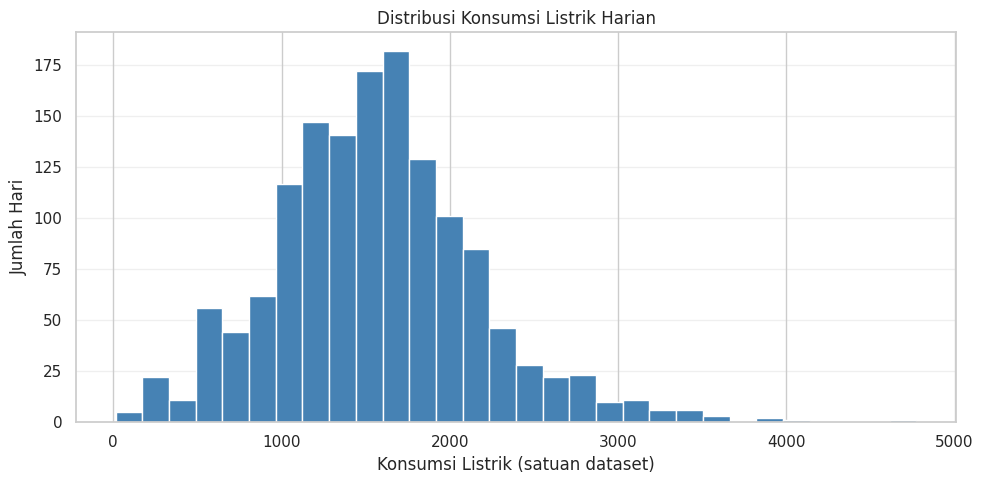

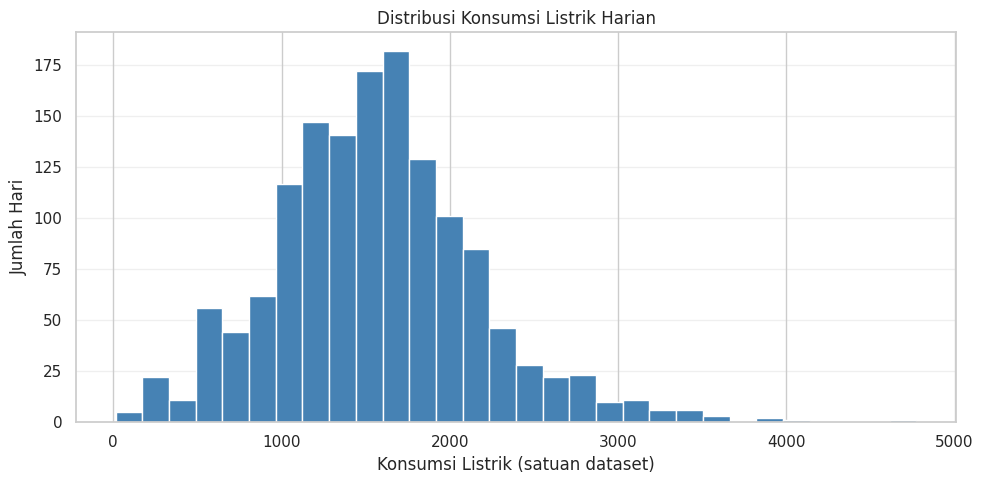

In [ ]:
# Model 10: Histogram Konsumsi Listrik

g1, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    data["Listrik"].dropna(),
    bins=30,
    color="steelblue",
    edgecolor="white"
)

ax.set_title("Distribusi Konsumsi Listrik Harian")
ax.set_xlabel("Konsumsi Listrik (satuan dataset)")
ax.set_ylabel("Jumlah Hari")
ax.grid(axis="y", alpha=0.3)

g1.tight_layout()
display(g1)

**Grafik konsumsi listrik harian berdasarkan tanggal**

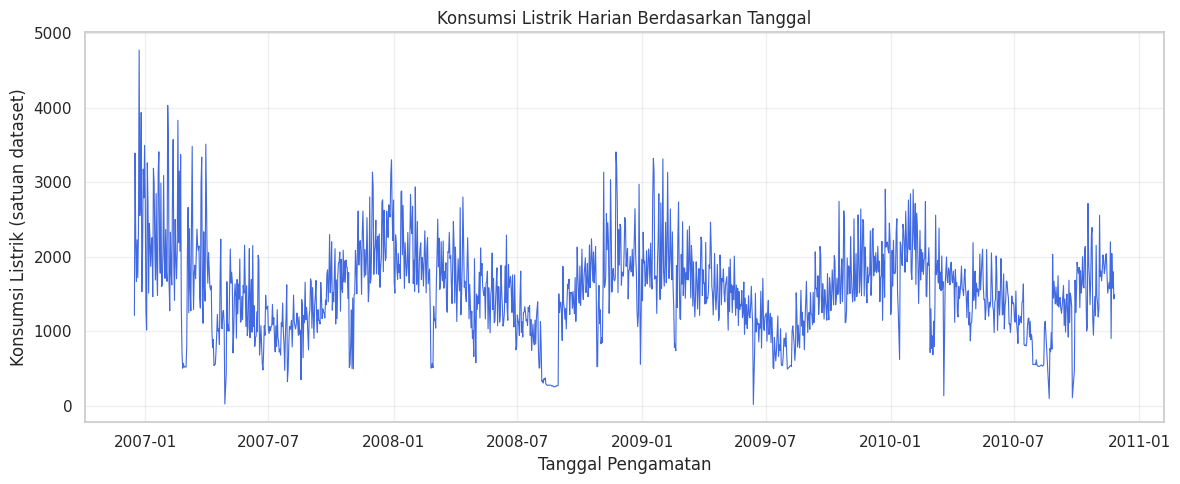

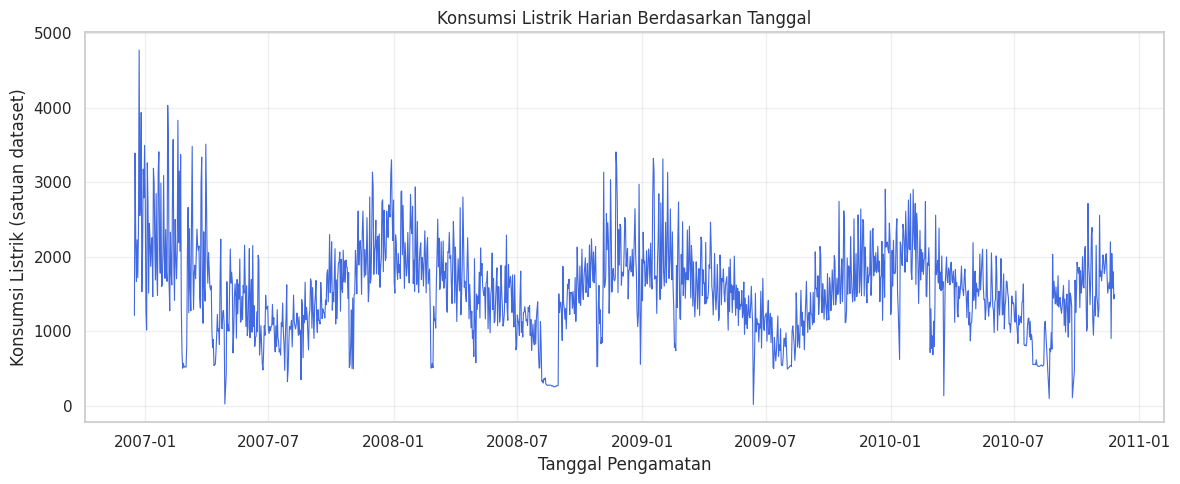

In [ ]:
# Model 11: Grafik Deret Waktu Harian

g2, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    data["Tanggal"],
    data["Listrik"],
    color="royalblue",
    linewidth=0.8
)

ax.set_title("Konsumsi Listrik Harian Berdasarkan Tanggal")
ax.set_xlabel("Tanggal Pengamatan")
ax.set_ylabel("Konsumsi Listrik (satuan dataset)")
ax.grid(alpha=0.3)

g2.tight_layout()
display(g2)

**Grafik rata-rata konsumsi listrik bulanan**

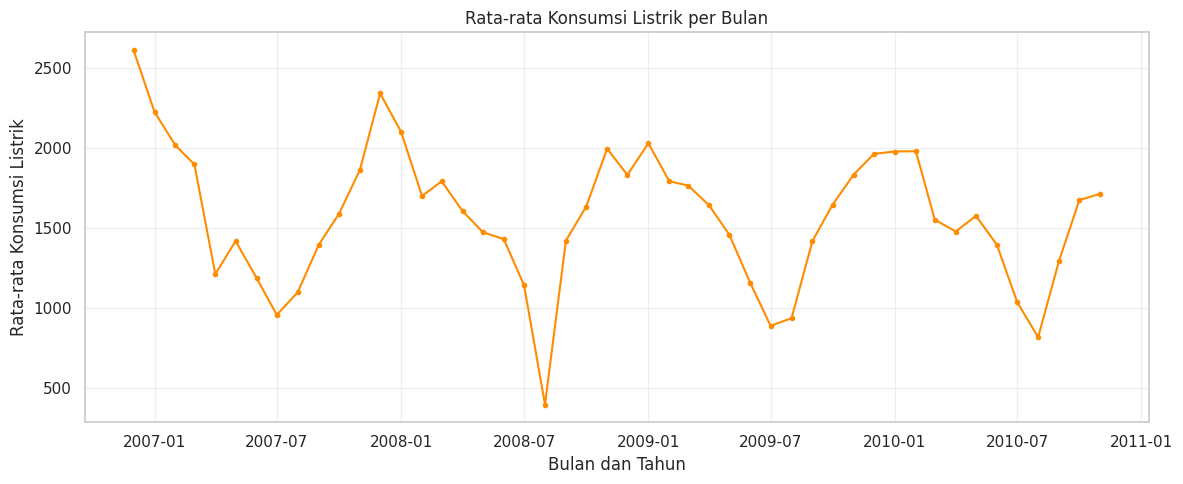

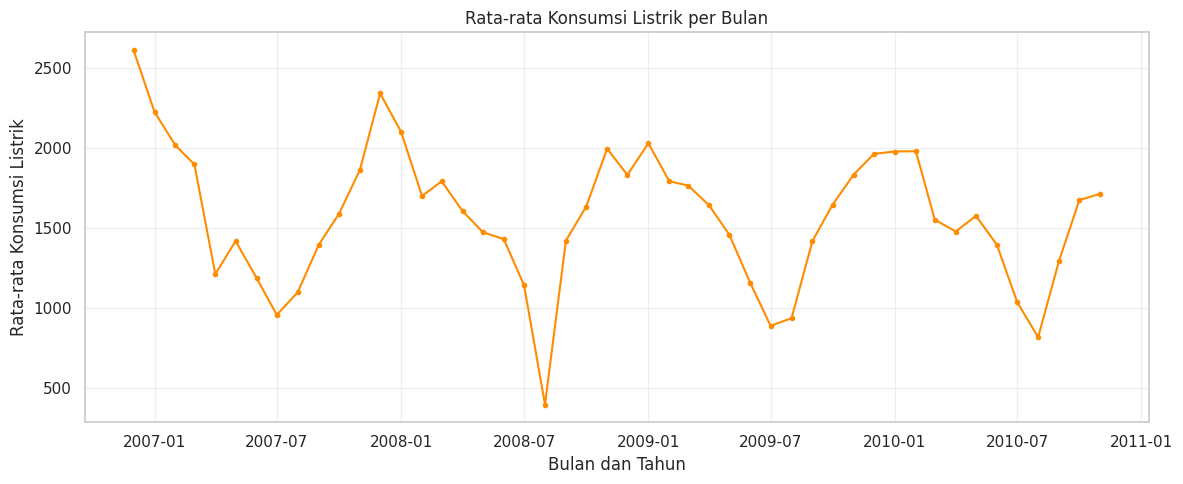

In [ ]:
# Model 12: Grafik Rata-rata Konsumsi Bulanan

g3, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    tabel_bulan["Bulan"],
    tabel_bulan["Rata-rata Listrik"],
    marker="o",
    markersize=3,
    linewidth=1.5,
    color="darkorange"
)

ax.set_title("Rata-rata Konsumsi Listrik per Bulan")
ax.set_xlabel("Bulan dan Tahun")
ax.set_ylabel("Rata-rata Konsumsi Listrik")
ax.grid(alpha=0.3)

g3.tight_layout()
display(g3)

**Grafik rata-rata konsumsi menurut hari dalam seminggu**

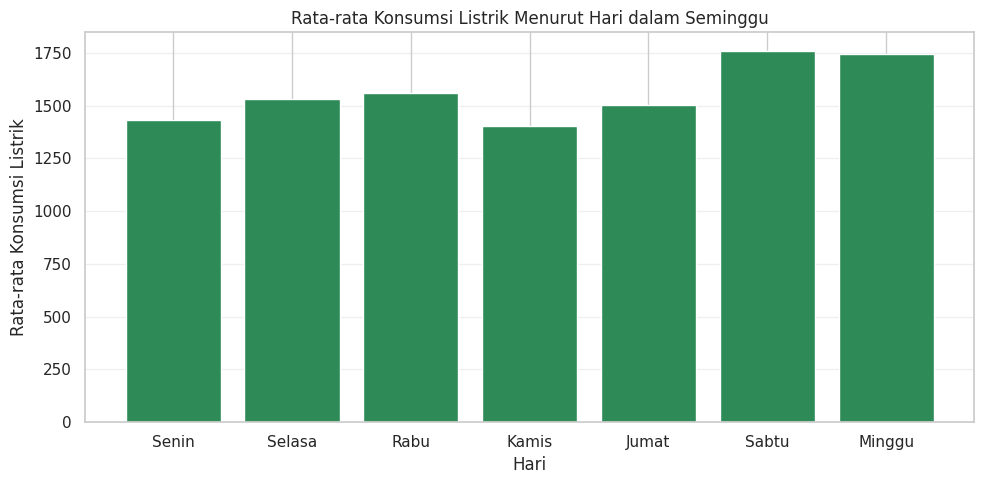

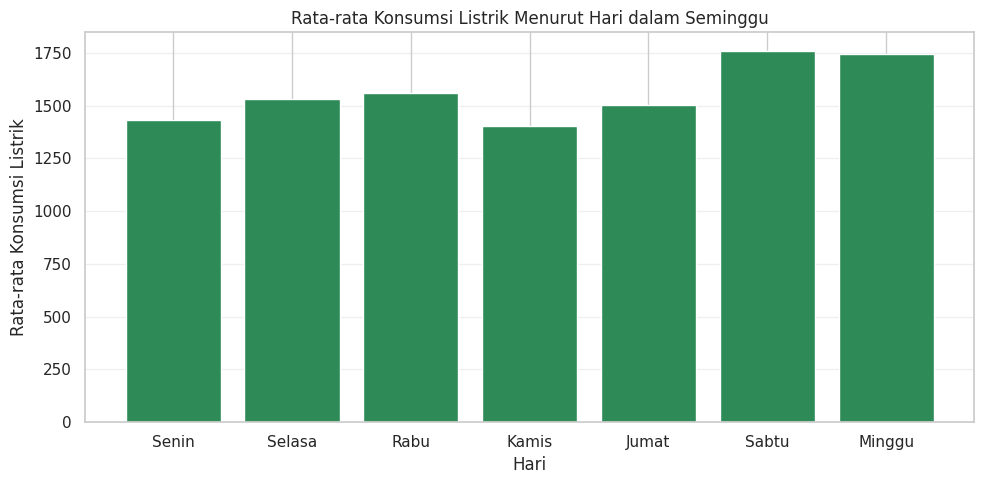

In [ ]:
# Model 13: Grafik Rata-rata Berdasarkan Hari

g4, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    tabel_hari.index,
    tabel_hari["Rata-rata Listrik"],
    color="seagreen"
)

ax.set_title("Rata-rata Konsumsi Listrik Menurut Hari dalam Seminggu")
ax.set_xlabel("Hari")
ax.set_ylabel("Rata-rata Konsumsi Listrik")
ax.grid(axis="y", alpha=0.3)

g4.tight_layout()
display(g4)

**Grafik ringkasan konsumsi berdasarkan kondisi hujan**

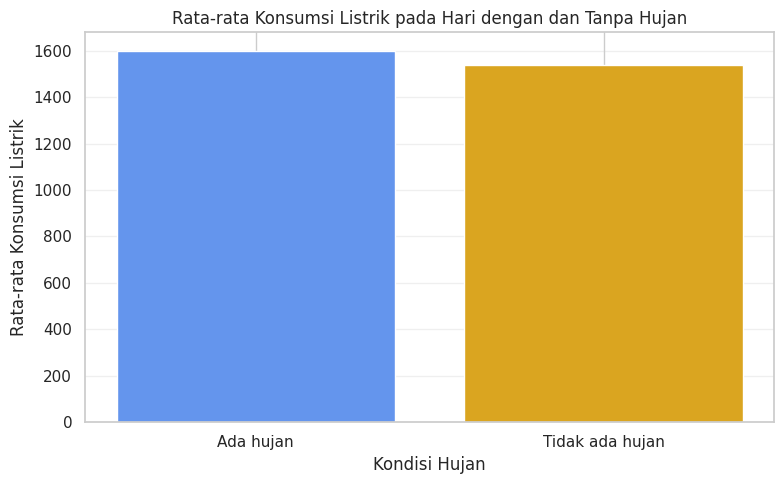

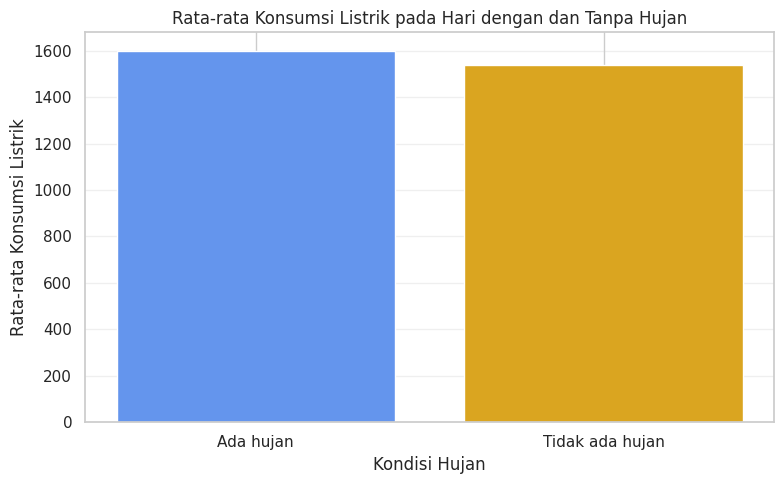

In [ ]:
# Model 14: Grafik Konsumsi pada Hari dengan dan Tanpa Hujan

g5, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    tabel_cuaca.index,
    tabel_cuaca["Rata-rata Listrik"],
    color=["cornflowerblue", "goldenrod"]
)

ax.set_title("Rata-rata Konsumsi Listrik pada Hari dengan dan Tanpa Hujan")
ax.set_xlabel("Kondisi Hujan")
ax.set_ylabel("Rata-rata Konsumsi Listrik")
ax.grid(axis="y", alpha=0.3)

g5.tight_layout()
display(g5)

**Grafik distribusi variabel cuaca**

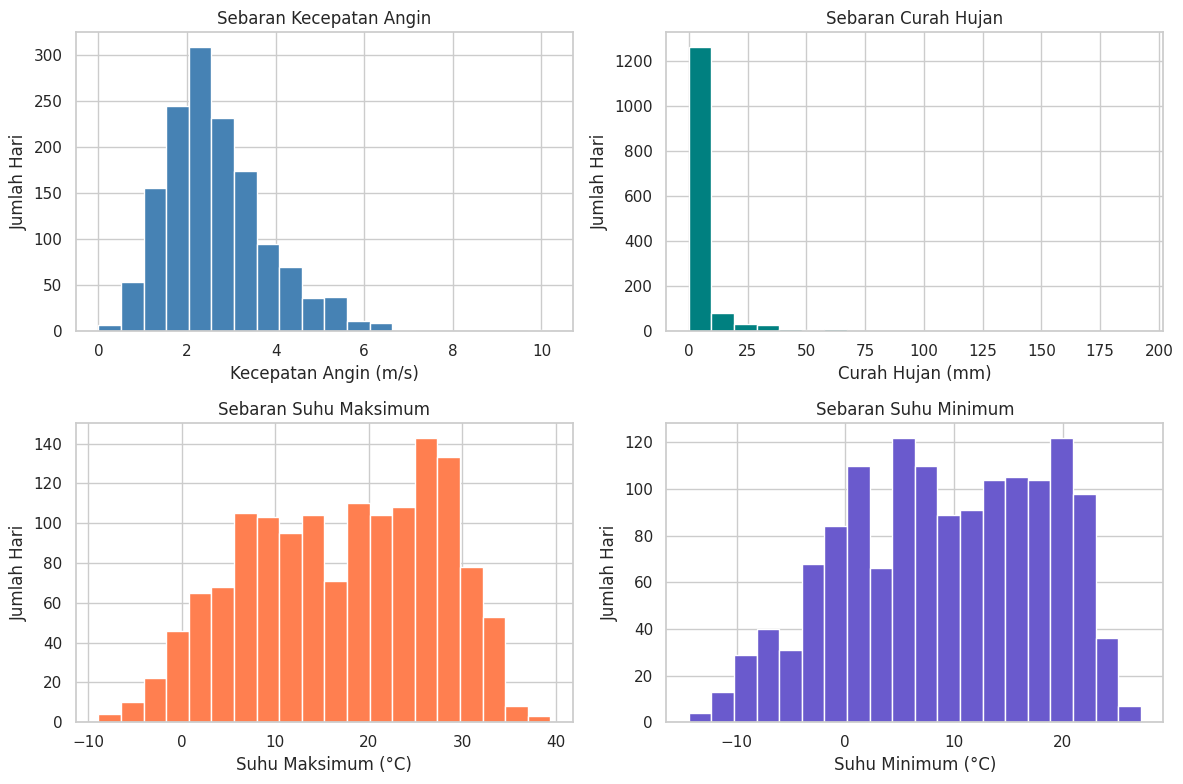

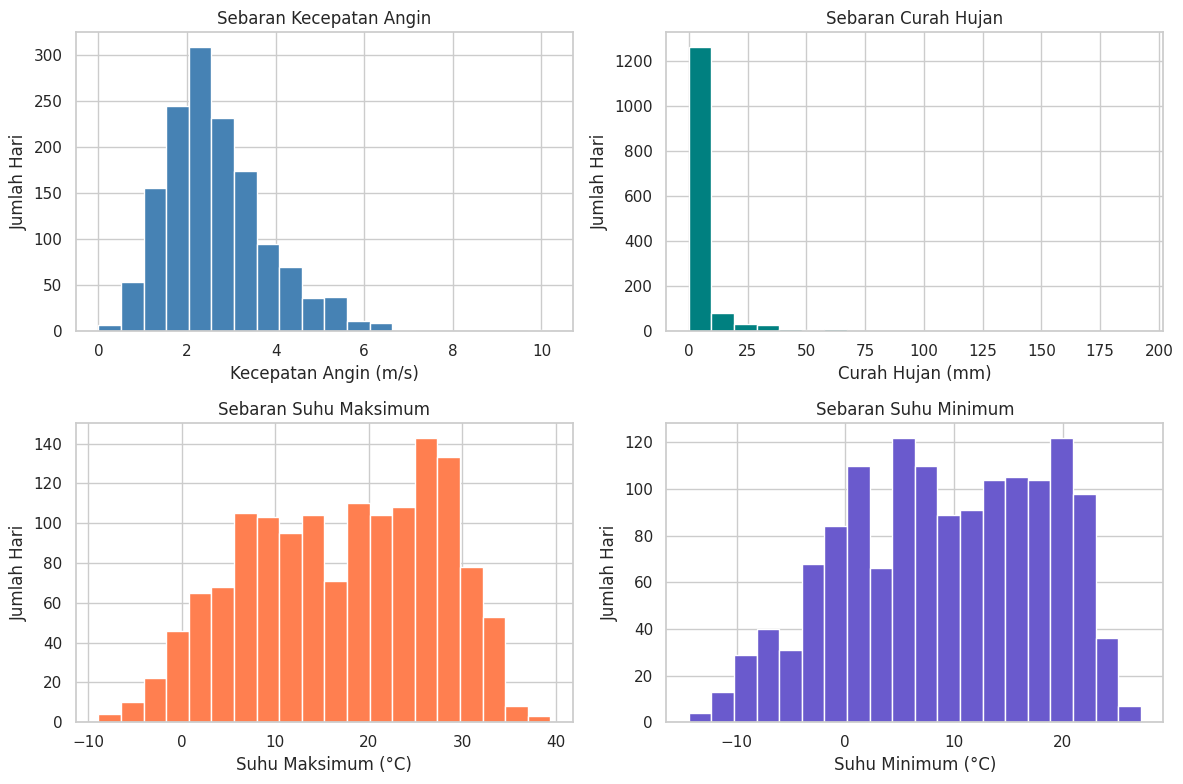

In [ ]:
# Model 15: Distribusi Variabel Cuaca

g6, ax = plt.subplots(2, 2, figsize=(12, 8))

ax[0, 0].hist(data["Angin"].dropna(), bins=20, color="steelblue", edgecolor="white")
ax[0, 0].set_title("Sebaran Kecepatan Angin")
ax[0, 0].set_xlabel("Kecepatan Angin (m/s)")
ax[0, 0].set_ylabel("Jumlah Hari")

ax[0, 1].hist(data["Hujan"].dropna(), bins=20, color="teal", edgecolor="white")
ax[0, 1].set_title("Sebaran Curah Hujan")
ax[0, 1].set_xlabel("Curah Hujan (mm)")
ax[0, 1].set_ylabel("Jumlah Hari")

ax[1, 0].hist(data["Suhu_Maks"].dropna(), bins=20, color="coral", edgecolor="white")
ax[1, 0].set_title("Sebaran Suhu Maksimum")
ax[1, 0].set_xlabel("Suhu Maksimum (°C)")
ax[1, 0].set_ylabel("Jumlah Hari")

ax[1, 1].hist(data["Suhu_Min"].dropna(), bins=20, color="slateblue", edgecolor="white")
ax[1, 1].set_title("Sebaran Suhu Minimum")
ax[1, 1].set_xlabel("Suhu Minimum (°C)")
ax[1, 1].set_ylabel("Jumlah Hari")

g6.tight_layout()
display(g6)

**Grafik frekuensi kategori konsumsi listrik**

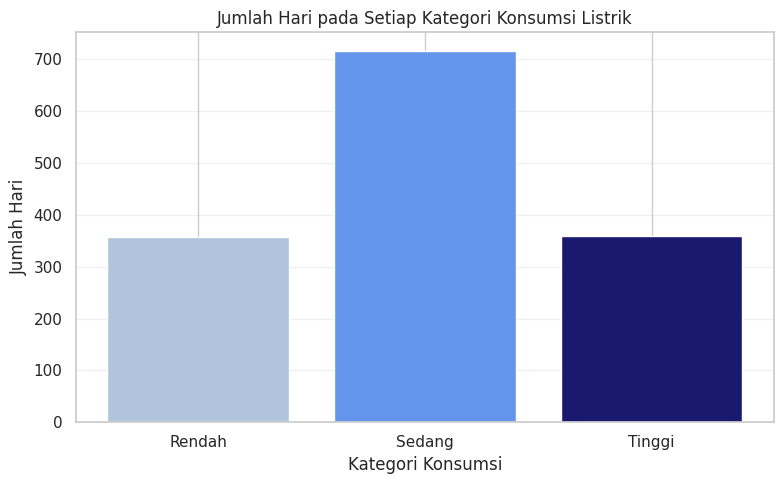

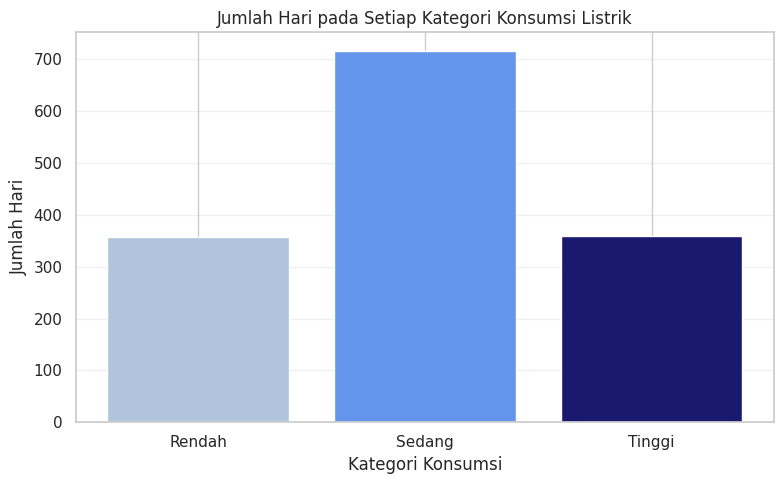

In [ ]:
# Model 16: Grafik Frekuensi Kategori Konsumsi

g7, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    tabel_freq["Kategori"],
    tabel_freq["Jumlah Hari"],
    color=["lightsteelblue", "cornflowerblue", "midnightblue"]
)

ax.set_title("Jumlah Hari pada Setiap Kategori Konsumsi Listrik")
ax.set_xlabel("Kategori Konsumsi")
ax.set_ylabel("Jumlah Hari")
ax.grid(axis="y", alpha=0.3)

g7.tight_layout()
display(g7)

# **BAGIAN 7 — Dashboard akhir**

,Tanggal,Angin,Hujan,Suhu_Maks,Suhu_Min,Listrik
0,2006-12-16,2.5,0.0,10.6,5.0,1209.176
1,2006-12-17,2.6,0.0,13.3,5.6,3390.460
2,2006-12-18,2.4,0.0,15.0,6.7,2203.826
3,2006-12-19,2.4,0.0,7.2,2.2,1666.194
4,2006-12-20,2.4,0.0,7.2,1.1,2225.748
...,...,...,...,...,...,...
1428,2010-11-22,2.7,0.0,18.3,7.2,2041.536
1429,2010-11-23,3.1,0.0,16.1,10.0,1577.536
1430,2010-11-24,4.3,0.0,10.0,5.0,1796.248
1431,2010-11-25,1.6,1.5,7.8,3.9,1431.164


,Variabel,Jenis Data,Skala Pengukuran,Keterangan
0,Tanggal,Tanggal/waktu,Interval (temporal),Menunjukkan tanggal pengamatan
1,Kecepatan Angin,Numerik kontinu,Rasio,Kecepatan angin dalam m/s
2,Curah Hujan,Numerik kontinu,Rasio,Curah hujan dalam mm
3,Suhu Maksimum,Numerik kontinu,Interval,Suhu dalam Celsius
4,Suhu Minimum,Numerik kontinu,Interval,Suhu dalam Celsius
5,Konsumsi Listrik Harian,Numerik,Rasio,Satuan tidak dicantumkan dalam file


,Variabel,Count,Jumlah,Mean,Modus,Median,SE,Std Dev,Varian,Q1,Q2,Q3,IQR,Skewness,Kurtosis,Min,Max,Range,CV (%)
0,Kecepatan Angin (m/s),1433,3775.900,2.635,2.200,2.40,0.030,1.137,1.292,1.8,2.40,3.200,1.400,0.975,1.835,0.000,10.200,10.200,43.146
1,Curah Hujan (mm),1433,5446.100,3.800,0.000,0.00,0.290,10.973,120.416,0.0,0.00,1.300,1.300,6.371,72.460,0.000,192.300,192.300,288.738
2,Suhu Maksimum (°C),1433,24629.700,17.188,28.300,17.80,0.268,10.136,102.747,8.9,17.80,26.100,17.200,-0.213,-0.990,-8.900,39.400,48.300,NaN
3,Suhu Minimum (°C),1433,13099.400,9.141,19.400,9.40,0.239,9.028,81.512,2.2,9.40,17.200,15.000,-0.236,-0.871,-14.400,27.200,41.600,NaN
4,Konsumsi Listrik Harian,1433,2237024.862,1561.078,Tidak ada modus tunggal,1542.65,16.030,606.820,368230.109,1165.7,1542.65,1893.608,727.908,0.520,1.215,14.218,4773.386,4759.168,38.872


,Variabel,Jumlah Data,Rata-rata,Nilai Tengah,Standar Deviasi,Nilai Minimum,Nilai Maksimum
0,Kecepatan Angin (m/s),1433,2.635,2.40,1.137,0.000,10.200
1,Curah Hujan (mm),1433,3.800,0.00,10.973,0.000,192.300
2,Suhu Maksimum (°C),1433,17.188,17.80,10.136,-8.900,39.400
3,Suhu Minimum (°C),1433,9.141,9.40,9.028,-14.400,27.200
4,Konsumsi Listrik Harian,1433,1561.078,1542.65,606.820,14.218,4773.386


,Kategori,Jumlah Hari,Persentase (%)
0,Rendah,358,24.98
1,Sedang,716,49.97
2,Tinggi,359,25.05


,Keterangan,Nilai
0,Batas konsumsi tinggi (Q3),1893.608
1,Jumlah hari dengan konsumsi tinggi,359.000
2,Jumlah hari dengan data valid,1433.000
3,Proporsi empiris konsumsi tinggi (%),25.050


,Jumlah Hari,Rata-rata Listrik,Median Listrik,Nilai Minimum,Nilai Maksimum
Hari,,,,,
Senin,205,1432.852,1443.260,250.298,3212.998
Selasa,206,1530.587,1518.774,257.564,3934.110
Rabu,204,1558.390,1583.147,258.114,3134.930
Kamis,205,1404.026,1394.186,261.298,3369.478
Jumat,205,1501.536,1497.768,267.124,3174.392
Sabtu,205,1758.770,1733.138,14.218,4773.386
Minggu,203,1743.300,1674.356,93.338,3829.762


,Jumlah Hari,Rata-rata Listrik,Median Listrik,Nilai Minimum,Nilai Maksimum
Cuaca,,,,,
Ada hujan,500,1599.327,1563.065,14.218,4773.386
Tidak ada hujan,933,1540.581,1521.344,22.738,4029.722


,Bulan,Jumlah Hari,Rata-rata Listrik,Median Listrik
0,2006-12-01,16,2613.330,2445.675
1,2007-01-01,31,2226.189,2154.800
2,2007-02-01,28,2017.460,1851.185
3,2007-03-01,31,1898.780,1884.814
4,2007-04-01,29,1213.154,1054.566
5,2007-05-01,31,1419.641,1467.782
6,2007-06-01,30,1189.428,1066.008
7,2007-07-01,31,958.188,991.018
8,2007-08-01,31,1099.886,1112.312
9,2007-09-01,30,1395.754,1345.513


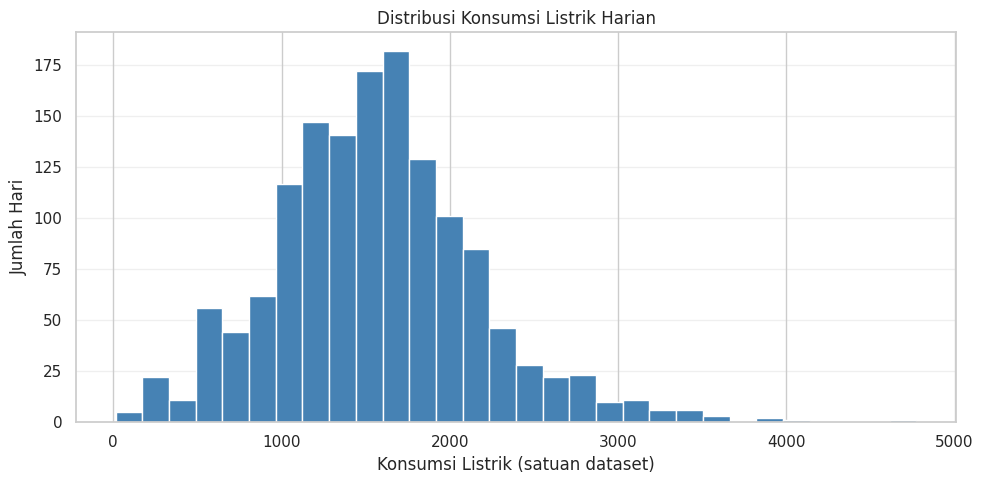

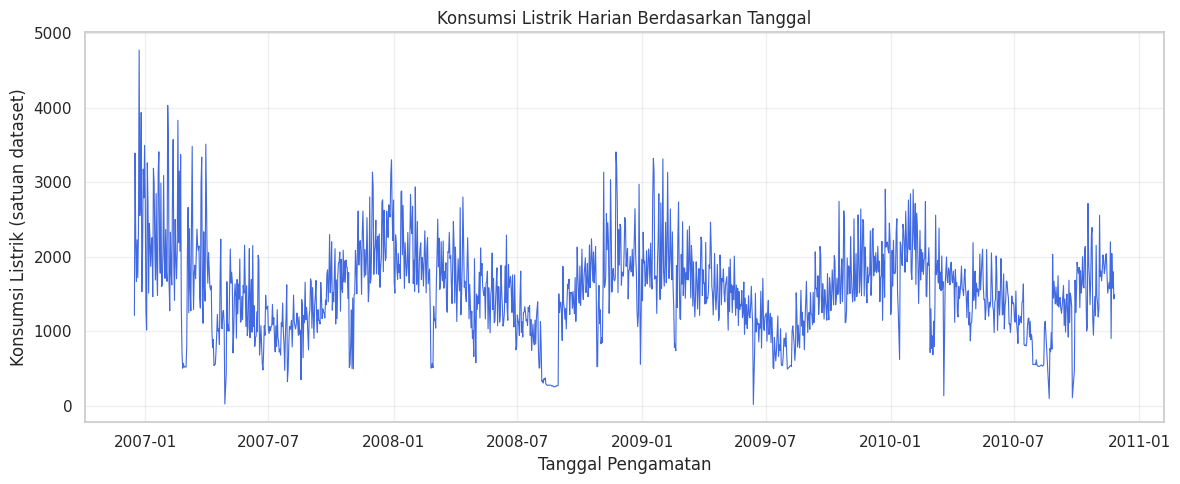

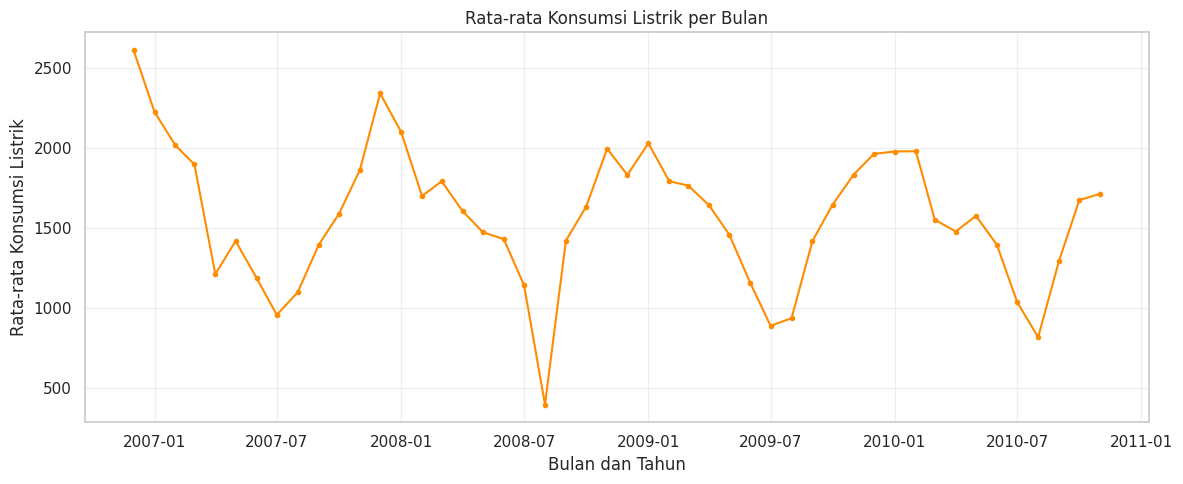

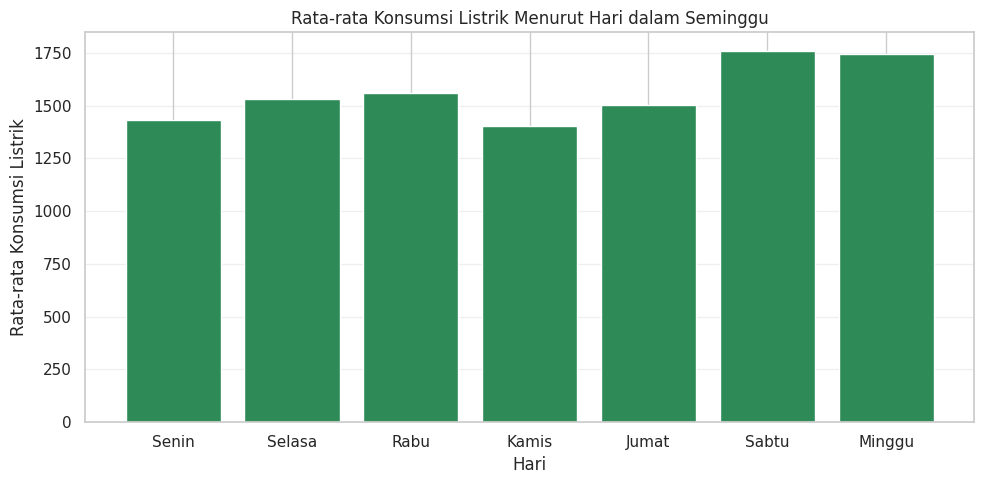

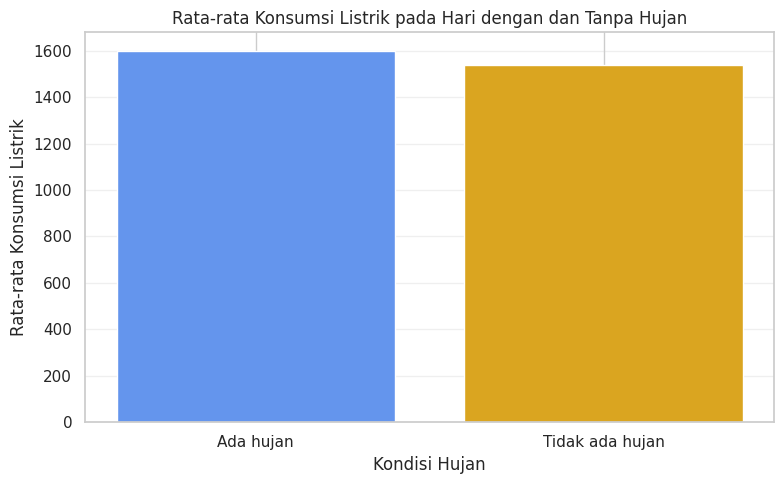

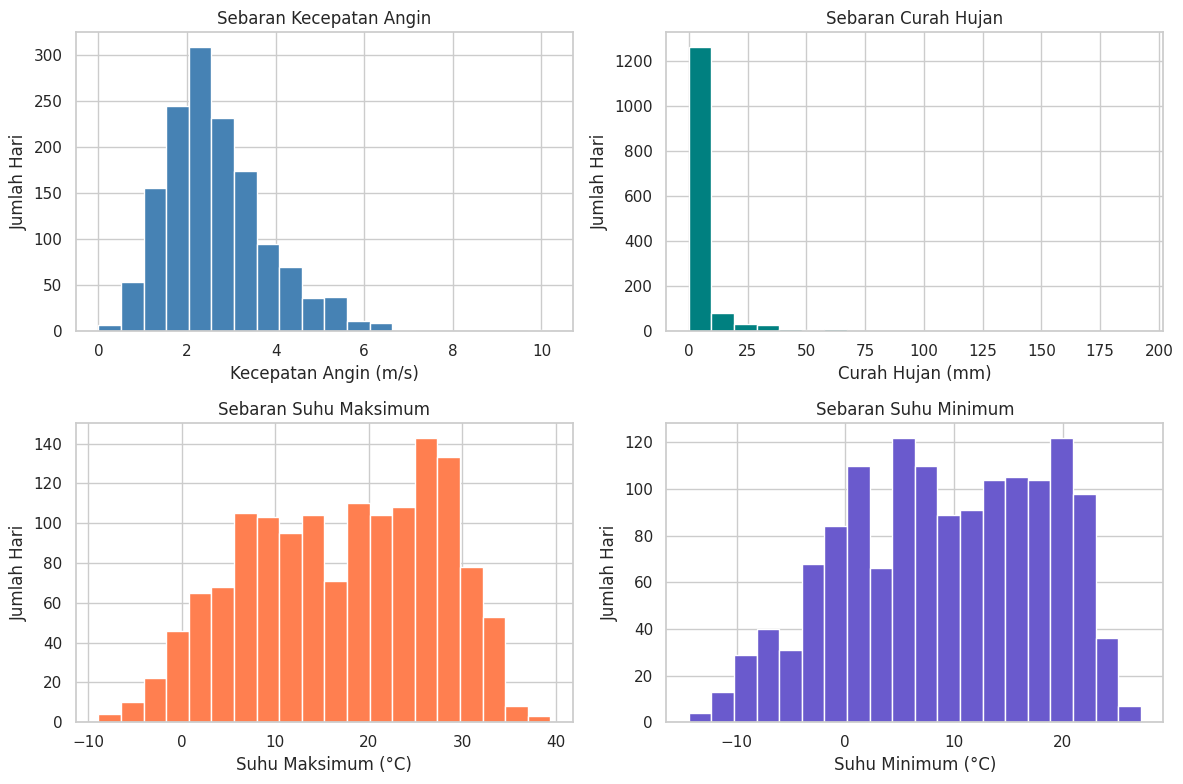

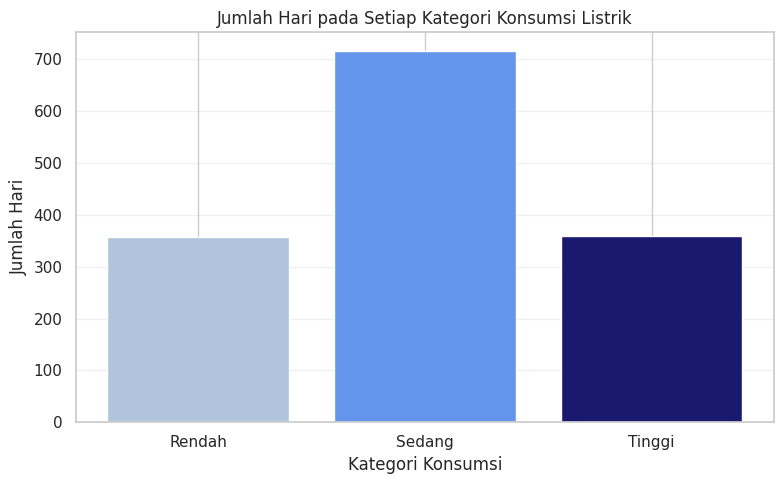

In [ ]:
# Model 17: Dashboard Analisis Konsumsi Listrik

from google.colab import data_table

# Membuat tampilan judul dashboard
display(HTML(f"""
<div style="
    background-color:#17324d;
    color:white;
    padding:24px;
    border-radius:12px;
    margin-bottom:18px;
">
    <h1 style="margin:0;">
        Dashboard Analisis Konsumsi Listrik Harian
    </h1>
    <p style="margin:10px 0 0 0;">
        Analisis Statistika Deskriptif Konsumsi Listrik Harian
        Berdasarkan Waktu dan Kondisi Cuaca
    </p>
    <p style="margin:8px 0 0 0;">
        Periode: {awal.date()} hingga {akhir.date()}
    </p>
</div>
"""))

# Ringkasan utama
display(HTML("<h2>1. Ringkasan Dataset</h2>"))

display(HTML(f"""
<div style="
    display:flex;
    flex-wrap:wrap;
    gap:12px;
    margin-bottom:18px;
">
    <div style="background:#e8f1fb;padding:16px;border-radius:8px;min-width:150px;">
        <b>Jumlah Observasi</b>
        <h2 style="color:#17324d;">{len(data_asli):,}</h2>
    </div>

    <div style="background:#e8f1fb;padding:16px;border-radius:8px;min-width:150px;">
        <b>Jumlah Variabel</b>
        <h2 style="color:#17324d;">{len(data_asli.columns)}</h2>
    </div>

    <div style="background:#e8f1fb;padding:16px;border-radius:8px;min-width:180px;">
        <b>Rata-rata Konsumsi</b>
        <h2 style="color:#17324d;">{data_asli["Listrik"].mean():,.2f}</h2>
    </div>

    <div style="background:#e8f1fb;padding:16px;border-radius:8px;min-width:180px;">
        <b>Median Konsumsi</b>
        <h2 style="color:#17324d;">{data_asli["Listrik"].median():,.2f}</h2>
    </div>
</div>
"""))

# Dataset asli dengan tampilan interaktif
display(HTML("<h2>2. Dataset Lengkap</h2>"))

display(HTML("""
<p>
Tabel berikut memuat seluruh data yang digunakan.
Gunakan halaman tabel untuk menelusuri baris lainnya.
</p>
"""))

display(
    data_table.DataTable(
        data_asli,
        include_index=False,
        num_rows_per_page=10
    )
)

# Tabel jenis variabel
display(HTML("<h2>3. Jenis Data dan Skala Pengukuran</h2>"))
display(tabel_skala)

# Tabel statistik lengkap
display(HTML("<h2>4. Statistik Deskriptif Lengkap</h2>"))
display(tabel_stat.round(3))

# Tabel resume singkat
display(HTML("<h2>5. Tabel Resume</h2>"))
display(tabel_resume.round(3))

# Tabel frekuensi dan peluang empiris
display(HTML("<h2>6. Tabel Frekuensi Konsumsi Listrik</h2>"))
display(tabel_freq)

display(HTML("<h3>Probabilitas Empiris</h3>"))
display(tabel_emp)

# Tabel berdasarkan waktu
display(HTML("<h2>7. Ringkasan Berdasarkan Hari</h2>"))
display(tabel_hari.round(3))

display(HTML("<h2>8. Ringkasan Berdasarkan Kondisi Hujan</h2>"))
display(tabel_cuaca.round(3))

display(HTML("<h2>9. Ringkasan Konsumsi Bulanan</h2>"))
display(tabel_bulan.round(3))

# Menampilkan semua grafik
display(HTML("<h2>10. Kumpulan Grafik Analisis</h2>"))

display(g1)
display(g2)
display(g3)
display(g4)
display(g5)
display(g6)
display(g7)

display(HTML("""
<div style="
    background-color:#000000;
    padding:16px;
    border-radius:8px;
    margin-top:15px;

">
    <h3 style="color:#ffffff;">Penutup</h3>
    <p>
    Dashboard ini merangkum dataset, statistik deskriptif,
    tabel frekuensi, ringkasan berdasarkan waktu dan kondisi hujan,
    serta grafik yang menggambarkan data selama periode pengamatan.
    Seluruh hasil digunakan untuk mendeskripsikan data yang tersedia.
    </p>
</div>
"""))